# manasight 06: where the errors come from, and color as several yes/no questions

Notebooks 05, 05b and 05c trained three very different models and all three stopped near 45% on color.
Before trying anything bigger, this notebook looks at the 55% that are wrong.

**Hypothesis H7:** multicolor art blends the cues of its colors. A red-green card should look partly Red and partly
Green to the model, not like a separate kind of picture called "Multicolor".

Sections:
1. Load data, features and the linear probe
2. What happens to multicolor cards
3. The most confident mistakes
4. Does the model know when it knows?
5. Errors by set and by type
6. Color as five yes/no questions (multi-label)
7. Reading the five scores
8. Turning scores into a final answer
9. Summary

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, f1_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, load_cards
from manasight.clip import load_image_features
from manasight.eda import load_thumbnails
from manasight.features import color_histogram
from manasight.evaluate import score

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]   # paintings: jpeg keeps the notebook small

## 1. Load data, features and the linear probe

The same linear probe as in notebook 05 (frozen CLIP features, logistic regression, C = 0.001), trained again here
so we can look at its individual answers.

In [2]:
all_cards = load_cards()
not_junk = ~all_cards.is_junk.to_numpy()
cards = all_cards[not_junk].reset_index(drop=True)
features = load_image_features(cards)

is_train = (cards.split == "train").to_numpy()
is_val = (cards.split == "val").to_numpy()
is_test = (cards.split == "test").to_numpy()
x = StandardScaler().fit(features[is_train]).transform(features)

probe = LogisticRegression(C=0.001, max_iter=200).fit(x[is_train], cards.color[is_train])
probabilities = probe.predict_proba(x[is_test])

test_cards = cards[is_test].reset_index(drop=True)
test_cards["predicted"] = probe.classes_[probabilities.argmax(axis=1)]
test_cards["confidence"] = probabilities.max(axis=1)
test_cards["correct"] = test_cards.predicted == test_cards.color
print(f"test accuracy: {test_cards.correct.mean():.3f}   ({(~test_cards.correct).sum():,} of {len(test_cards):,} wrong)")

test accuracy: 0.446   (1,879 of 3,392 wrong)


## 2. What happens to multicolor cards

A fifth of the test set is Multicolor, and the probe finds only 19% of it. What does it answer instead?
For a green-white card, "Green" is not a blind guess: the card really is green.

In [3]:
multicolor = test_cards[test_cards.color == "Multicolor"]
says_multicolor = (multicolor.predicted == "Multicolor").to_numpy()
says_own_color = np.array([predicted in identity for predicted, identity in zip(multicolor.predicted, multicolor.color_identity)])

print(f"multicolor test cards: {len(multicolor)}")
print(f'answered "Multicolor" (counted right):           {says_multicolor.mean():.1%}')
print(f"answered one of the card's own colors (wrong):   {says_own_color.mean():.1%}")
print(f"answered something else:                         {1 - says_multicolor.mean() - says_own_color.mean():.1%}")

lenient_right = test_cards.correct.sum() + says_own_color.sum()
print(f'\nif "one of its own colors" counted as right: accuracy {lenient_right / len(test_cards):.3f} instead of {test_cards.correct.mean():.3f}')

multicolor test cards: 685
answered "Multicolor" (counted right):           19.3%
answered one of the card's own colors (wrong):   60.3%
answered something else:                         20.4%

if "one of its own colors" counted as right: accuracy 0.568 instead of 0.446


**Finding:** for 60% of the multicolor cards the probe names a color the card really has, and is marked wrong.
Only one in five multicolor "errors" is a wrong color. Counting "one of its own colors" as right would put the
overall accuracy at 57% instead of 45%.

So a large part of the missing accuracy is not the model failing to see the art. It is the class "Multicolor" itself:
a rule of the game ("has two or more colors"), with no look of its own (notebook 04 found only city words for it,
notebook 05 only "different, varied").

## 3. The most confident mistakes

The wrong answers the probe was most sure about.

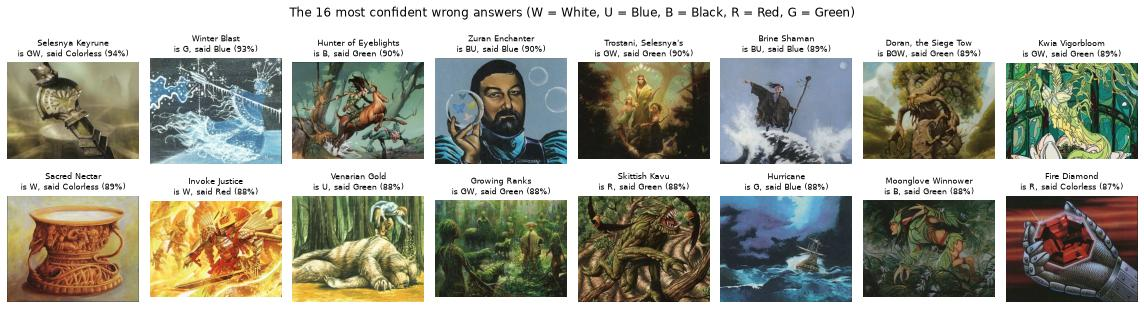

                      name set        type color_identity predicted  confidence
          Selesnya Keyrune rtr    Artifact             GW Colorless        0.94
              Winter Blast leg     Sorcery              G         U        0.93
      Hunter of Eyeblights lrw    Creature              B         G        0.90
           Zuran Enchanter ice    Creature             BU         U        0.90
Trostani, Selesnya's Voice rtr    Creature             GW         G        0.90
              Brine Shaman ice    Creature             BU         U        0.89
    Doran, the Siege Tower lrw    Creature            BGW         G        0.89
           Kwia Vigorbloom fra    Creature             GW         G        0.89
             Sacred Nectar 7ed     Sorcery              W Colorless        0.89
            Invoke Justice neo     Sorcery              W         R        0.88
             Venarian Gold leg Enchantment              U         G        0.88
             Growing Ranks rtr Enchantme

In [4]:
worst = test_cards[~test_cards.correct].sort_values("confidence", ascending=False).head(16)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, card in zip(axes.flat, worst.itertuples()):
    ax.imshow(Image.open(card.path))
    identity = card.color_identity if card.color_identity else "none"
    ax.set_title(f"{card.name[:20]}\nis {identity}, said {COLOR_NAMES[card.predicted]} ({card.confidence:.0%})", fontsize=8)
    ax.axis("off")
plt.suptitle("The 16 most confident wrong answers (W = White, U = Blue, B = Black, R = Red, G = Green)", fontsize=12)
plt.tight_layout()
plt.show()

print(worst[["name", "set", "type", "color_identity", "predicted", "confidence"]].round(2).to_string(index=False))

**Finding:** most of these are defensible, and they fall into three groups:
- **Multicolor cards answered with one of their own colors** (green-white Trostani as Green, the green-white-black
  Doran as Green).
- **Objects with a color identity answered as Colorless** (Selesnya Keyrune, Fire Diamond). The picture shows an
  artifact; the color comes from the rules text, which the model never sees.
- **Art that shows another color's theme** (Winter Blast and Hurricane are green spells that depict ice and storm;
  the probe says Blue).

Very few are the model being blind. They are cases where the picture and the label disagree.

## 4. Does the model know when it knows?

If the errors come from pictures that really are ambiguous, the probe should be unsure on those and sure on the
clear ones. Test cards sorted into groups by how confident the probe was:

In [5]:
edges = [0, 0.3, 0.4, 0.5, 0.7, 1.01]
group_names = ["under 30%", "30 to 40%", "40 to 50%", "50 to 70%", "over 70%"]
test_cards["confidence group"] = pd.cut(test_cards.confidence, edges, labels=group_names, right=False)
by_confidence = test_cards.groupby("confidence group", observed=True).agg(cards=("correct", "size"), accuracy=("correct", "mean"))
by_confidence["share of test set"] = by_confidence.cards / len(test_cards)
by_confidence.round(3)

,cards,accuracy,share of test set
confidence group,,,
under 30%,482,0.278,0.142
30 to 40%,994,0.341,0.293
40 to 50%,701,0.447,0.207
50 to 70%,829,0.540,0.244
over 70%,386,0.723,0.114


**Finding:** yes. When the probe is over 70% sure it is right 72% of the time; when it is under 30% sure it is
right 28% of the time. Its confidence means what it says. That is how an honest model behaves on a task where
many inputs do not contain the answer, and it is useful for the app: a confident answer can be trusted more.

## 5. Errors by set and by type

In [6]:
test_cards["is_multicolor"] = test_cards.color == "Multicolor"
by_set = test_cards.groupby(["era", "set_name"]).agg(cards=("correct", "size"), accuracy=("correct", "mean"),
                                                     multicolor=("is_multicolor", "mean"))
by_type = test_cards.groupby("type").agg(cards=("correct", "size"), accuracy=("correct", "mean")).loc[TYPE_CLASSES]
single_color_creatures = test_cards[(test_cards.type == "Creature") & test_cards.color.isin(COLOR_CLASSES[:5])]

print(by_set.round(3).to_string())
print()
print(by_type.round(3).T.to_string())
print(f"\nsingle-color creatures only: {single_color_creatures.correct.mean():.3f}  ({len(single_color_creatures):,} cards)")

                                  cards  accuracy  multicolor
era   set_name                                               
1993  Ice Age                       363     0.347       0.132
      Legends                       310     0.358       0.181
1997  Invasion                      331     0.387       0.387
      Seventh Edition               331     0.634       0.015
2003  Lorwyn                        281     0.434       0.046
      Return to Ravnica             249     0.386       0.422
2015  Kamigawa: Neon Dynasty        402     0.550       0.159
      The Lost Caverns of Ixalan    355     0.496       0.180
2024+ Aetherdrift                   371     0.412       0.261
      Reality Fracture              399     0.426       0.263

type      Creature  Planeswalker     Land  Artifact  Enchantment  Instant  Sorcery
cards     1693.000        43.000  188.000   335.000      431.000  399.000  303.000
accuracy     0.478         0.558    0.346     0.385        0.434    0.444    0.399

singl

**Finding:**
- **The set matters most:** from 35% (Ice Age, Legends) to 63% (Seventh Edition). The two sets with the most
  multicolor cards, Invasion and Return to Ravnica, are near the bottom, which fits section 2.
- **The type matters less than expected:** creatures 48%, instants 44%, enchantments 43%, sorceries 40%.
  Lands (35%) and artifacts (39%) are hardest: their color comes from the rules, not from the picture.
- On single-color creatures, the clearest case, the probe is right 57% of the time.

(We also checked whether the sets made with outside franchises, such as Final Fantasy or The Lord of the Rings,
confuse the training. Leaving their 2,729 pictures out of training changes nothing: 44.8% against 44.6%.)

## 6. Color as five yes/no questions (multi-label)

The game does not have a color called "Multicolor". A card **has** White or not, **has** Blue or not, and so on:
five separate yes/no facts. A green-white card is yes for Green and White; a colorless card is five times no.

So we train **five small models, one per color**, each answering "does this card have this color?".
Same features and the same kind of classifier as the probe.

Each model gives a score from 0 to 1. To judge a score without choosing a cut-off yet, we use
**average precision**: rank all test cards by the score for, say, Red; average precision is high when the real red
cards are at the top of that list. A random ranking scores as low as the share of red cards (about 0.23).

In [7]:
five = ["W", "U", "B", "R", "G"]
has_color = np.array([[int(letter in identity) for letter in five] for identity in cards.color_identity])
print("cards with each color (test):", dict(zip(five, has_color[is_test].sum(axis=0))))
print("number of colors per test card:", pd.Series(has_color[is_test].sum(axis=1)).value_counts().sort_index().to_dict())

def train_five(inputs, C):
    # one yes/no model per color; returns the five scores for every card
    scores = np.zeros((len(inputs), 5))
    for column, letter in enumerate(five):
        model = LogisticRegression(C=C, max_iter=200).fit(inputs[is_train], has_color[is_train, column])
        scores[:, column] = model.predict_proba(inputs)[:, 1]
    return scores

clip_scores = train_five(x, C=0.001)

# the same five questions for the palette model of notebook 03
thumbs, sizes = load_thumbnails(all_cards)
histogram = color_histogram(thumbs[not_junk], bins=4)
histogram = StandardScaler().fit(histogram[is_train]).transform(histogram)
histogram_scores = train_five(histogram, C=1.0)

truth = has_color[is_test]
rows = []
for column, letter in enumerate(five):
    rows.append({"color": COLOR_NAMES[letter],
                 "random ranking": truth[:, column].mean(),
                 "color histogram": average_precision_score(truth[:, column], histogram_scores[is_test, column]),
                 "CLIP": average_precision_score(truth[:, column], clip_scores[is_test, column])})
average_precision = pd.DataFrame(rows).set_index("color")
average_precision.loc["average"] = average_precision.mean()
average_precision.round(3)

cards with each color (test): {'W': 789, 'U': 781, 'B': 789, 'R': 795, 'G': 774}
number of colors per test card: {0: 269, 1: 2438, 2: 597, 3: 72, 5: 16}


,random ranking,color histogram,CLIP
color,,,
White,0.233,0.352,0.548
Blue,0.230,0.461,0.595
Black,0.233,0.431,0.561
Red,0.234,0.594,0.692
Green,0.228,0.489,0.652
average,0.232,0.465,0.610


**Finding:** every color can be detected well above chance, and CLIP is far ahead of the palette on all five
(0.61 on average, against 0.47 for the histogram and 0.23 for a random ranking).
Red and Green are the easiest to detect, White and Black the hardest, the same order as in every notebook so far.

## 7. Reading the five scores

Three questions, each answered from the scores alone:

1. **Is the highest-scoring color one of the card's colors?** (for all cards that have a color)
2. **For one-color cards: is the highest-scoring color the right one?** (chance 20%)
3. **For two-color cards: are the two highest-scoring colors exactly the card's two colors?**
   There are 10 possible pairs, so chance is 10%. This is the test of H7.

And one overall check: are a card's own colors scored higher than the others?

In [8]:
test_scores = clip_scores[is_test]
test_histogram_scores = histogram_scores[is_test]
count = truth.sum(axis=1)
row_numbers = np.arange(len(truth))

def top_color_is_own(scores, rows):
    top = scores.argmax(axis=1)
    return truth[row_numbers, top][rows].mean()

def top_two_are_exact(scores, rows):
    hits = []
    for card_scores, card_truth in zip(scores[rows], truth[rows]):
        best_two = set(np.argsort(-card_scores)[:2])
        hits.append(best_two == set(np.where(card_truth == 1)[0]))
    return np.mean(hits)

with_color = count > 0
one_color = count == 1
two_colors = count == 2
table = pd.DataFrame({
    "cards": [with_color.sum(), one_color.sum(), two_colors.sum()],
    "chance": [np.nan, 0.2, 0.1],
    "color histogram": [top_color_is_own(test_histogram_scores, with_color), top_color_is_own(test_histogram_scores, one_color),
                        top_two_are_exact(test_histogram_scores, two_colors)],
    "CLIP": [top_color_is_own(test_scores, with_color), top_color_is_own(test_scores, one_color),
             top_two_are_exact(test_scores, two_colors)],
}, index=["1. top color is one of the card's", "2. one-color cards: top color right", "3. two-color cards: top two = the pair"])
print(f"average score of a card's own colors: {test_scores[truth == 1].mean():.3f}   of the other colors: {test_scores[truth == 0].mean():.3f}")
table.round(3)

average score of a card's own colors: 0.418   of the other colors: 0.166


,cards,chance,color histogram,CLIP
1. top color is one of the card's,3123,NaN,0.529,0.646
2. one-color cards: top color right,2438,0.2,0.481,0.597
3. two-color cards: top two = the pair,597,0.1,0.327,0.436


**Finding:**
- **The top-scoring color is one of the card's colors for 65% of all colored cards** (palette: 53%),
  and for one-color cards it is the right one 60% of the time (palette: 48%).
- **For two-color cards, the two top scores are exactly the card's pair 44% of the time,** against 10% by chance
  and 33% for the palette.
- A card's own colors score 0.42 on average, the other colors 0.17.

**H7 is supported.** A two-color card looks like both of its colors to the model. Multicolor art is not a third
kind of picture; it is a blend, and five yes/no scores describe it far better than one class did.

## 8. Turning scores into a final answer

For a final answer the scores need a cut-off: above it the card "has" the color. Two cut-offs are tried: the plain
0.5, and one per color chosen on the **validation** set (the value with the best F1 there).

Measures: F1 per color (averaged), **exact match** (all five yes/no answers right), and the answer converted back
to the 7 classes of the earlier notebooks (no color = Colorless, one = that color, more = Multicolor).

In [9]:
def to_seven_classes(answers):
    names = []
    for row in answers:
        if row.sum() == 0:
            names.append("Colorless")
        elif row.sum() == 1:
            names.append(five[row.argmax()])
        else:
            names.append("Multicolor")
    return np.array(names)

tuned = []
for column in range(5):
    best_f1 = 0
    best_cut = 0.5
    for cut in np.arange(0.10, 0.90, 0.02):
        f1 = f1_score(has_color[is_val, column], clip_scores[is_val, column] >= cut)
        if f1 > best_f1:
            best_f1 = f1
            best_cut = cut
    tuned.append(best_cut)
print("cut-offs chosen on validation:", dict(zip(five, np.round(tuned, 2))))

rows = []
for name, cuts in (("cut-off 0.5", np.full(5, 0.5)), ("cut-offs from validation", np.array(tuned))):
    answers = (test_scores >= cuts).astype(int)
    rows.append({"cut-off": name,
                 "F1 per color (average)": f1_score(truth, answers, average="macro"),
                 "exact match": (answers == truth).all(axis=1).mean(),
                 "as 7 classes": (to_seven_classes(answers) == test_cards.color.to_numpy()).mean(),
                 "cards answered with no color": (answers.sum(axis=1) == 0).mean(),
                 "with 2 or more": (answers.sum(axis=1) >= 2).mean()})
print(f"for comparison, the 7-class probe: accuracy {test_cards.correct.mean():.3f}")
pd.DataFrame(rows).set_index("cut-off").round(3)

cut-offs chosen on validation: {'W': 0.26, 'U': 0.3, 'B': 0.26, 'R': 0.28, 'G': 0.32}
for comparison, the 7-class probe: accuracy 0.446


,F1 per color (average),exact match,as 7 classes,cards answered with no color,with 2 or more
cut-off,,,,,
cut-off 0.5,0.470,0.345,0.347,0.430,0.035
cut-offs from validation,0.585,0.316,0.371,0.062,0.433


**Finding:** the scores are good, but turning them into one exact answer is hard.
- With the plain cut-off of 0.5 the models are too careful: 43% of the cards get no color at all.
- With cut-offs from validation the per-color F1 rises to 0.59, but now 43% of the cards get two or more colors,
  when only 20% have them.
- Either way **exact match (32% to 35%) is below the 7-class probe (44.6%)**. Getting five yes/no answers all right
  at once is a stricter test than picking one class, and deciding *how many* colors a card has is the weak point.

**Decision:** multi-label is the better description of a card, not a better headline number. For the app, the output
should be the five scores shown as a color breakdown ("mostly Green, some White"), with the single 7-class answer
next to it. The breakdown is where the model is honest and useful; a forced exact answer hides that.

## 9. Summary

**Where the errors come from**
- 60% of the multicolor cards are answered with one of their own colors and counted wrong. Counting those as right
  gives 57% instead of 45%.
- The most confident mistakes are mostly cases where picture and label disagree: multicolor cards, artifacts with a
  color identity, art that shows another color's theme.
- The probe's confidence is trustworthy: 72% right when it is over 70% sure.
- The set matters most (35% to 63%). Outside-franchise sets in the training data make no difference.

**Color as five yes/no questions**

| Test set | Color histogram | CLIP | Chance |
|---|---|---|---|
| Average precision per color (average of five) | 0.465 | 0.610 | 0.232 |
| Top color is one of the card's colors | 52.9% | 64.6% | |
| Two-color cards: top two are exactly the pair | 32.7% | 43.6% | 10% |
| Exact match of all five answers | | 31.6% to 34.5% | |

- **H7 supported:** multicolor art blends the cues of its colors.
- Multi-label describes cards better, but does not raise the exact-answer score.

**What this means for the 45% wall:** three models agreed on it, and this notebook shows why. A good part of the
"errors" are cards whose label is not in the picture. The model is not stuck; the question was partly unfair.

**Next:** the palette-or-content test: take the color out of the pictures (grayscale) and destroy the content
(shuffled pixels), and see what each model has left.